# Pertemuan 5: Machine Learning Supervised Learning for Regression

In [ ]:
import numpy as np
import pandas as pd

## Import Dataset

In [ ]:
data = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(data)

In [ ]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90000,0,yes,southwest,16884.92400
1,18,male,33.77000,1,no,southeast,1725.55230
2,28,male,33.00000,3,no,southeast,4449.46200
3,33,male,22.70500,0,no,northwest,21984.47061
4,32,male,28.88000,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.97000,3,no,northwest,10600.54830
1334,18,female,31.92000,0,no,northeast,2205.98080
1335,18,female,36.85000,0,no,southeast,1629.83350
1336,21,female,25.80000,0,no,southwest,2007.94500


In [ ]:
# Check for missing values
print("Missing values in the dataset:")
print(df.isnull().sum())

Missing values in the dataset:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [ ]:
# Convert categorical variables to numerical
df = pd.get_dummies(df, columns=['sex','smoker', 'region'])

In [ ]:
# Memisahkan fitur dan target
X = df.drop(columns=['charges'])
y = df['charges']

## Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error

In [ ]:
# Membagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Evaluation Function

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def train_and_evaluate_regression(model, X_train, X_test, y_train, y_test):
    # Melatih model dengan data latih
    model.fit(X_train, y_train)

    # Melakukan prediksi menggunakan data uji
    y_pred = model.predict(X_test)

    # Menghitung Mean Absolute Error (MAE)
    mae = mean_absolute_error(y_test, y_pred)

    # Menghitung Mean Squared Error (MSE)
    mse = mean_squared_error(y_test, y_pred)

    # Menghitung Root Mean Squared Error (RMSE)
    rmse = np.sqrt(mse)

    # Menghitung R-squared (Koefisien Determinasi)
    r2 = r2_score(y_test, y_pred)

    # Menyusun hasil evaluasi
    result = {'Mean Absolute Error': mae, 'Mean Squared Error': mse, 'Root Mean Squared Error': rmse, 'R-squared': r2}

    # Menampilkan hasil evaluasi
    print("Mean Absolute Error:", mae)
    print("Mean Squared Error:", mse)
    print("Root Mean Squared Error:", rmse)
    print("R-squared:", r2)

    return y_pred, result


## Pengertian Parameter dan Atribut

### Parameter
**Parameter** adalah variabel yang dapat diatur oleh pengguna saat membuat atau menginisialisasi suatu model. Parameter ini memengaruhi cara model bekerja atau berperilaku. Misalnya, dalam regresi linier, `fit_intercept` adalah parameter yang menentukan apakah model akan menghitung intersep (bias) atau tidak.

### Atribut
**Atribut** adalah variabel yang dihasilkan atau dihitung oleh model setelah proses pelatihan (fitting). Atribut ini memberikan informasi tentang model yang telah dilatih, seperti koefisien regresi (`coef_`) atau nilai intersep (`intercept_`).

## Model Regresi

### Linear Regression

<img src = "https://media.geeksforgeeks.org/wp-content/uploads/20231129130431/11111111.png" width = 70%></img>

```class sklearn.linear_model.LinearRegression(*, fit_intercept=True, copy_X=True, n_jobs=None, positive=False)```

Regresi Linier adalah metode statistik yang digunakan untuk memodelkan hubungan antara variabel dependen (target) dan satu atau lebih variabel independen (fitur). Tujuannya adalah menemukan garis lurus (hyperplane dalam kasus multidimensi) yang meminimalkan jumlah kuadrat residual antara nilai target yang diamati dan nilai target yang diprediksi.

#### Cara Mengestimasi
Model LinearRegression menggunakan metode **Ordinary Least Squares (OLS)** untuk mengestimasi koefisien. OLS bekerja dengan meminimalkan fungsi biaya berikut:

$$
\text{Minimize} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

Di mana:
- $ y_i $ adalah nilai target aktual.
- $ \hat{y}_i $ adalah nilai target yang diprediksi oleh model.
- $ n $ adalah jumlah sampel.

#### Parameter
- **fit_intercept** : bool, default=`True`  
  Menghitung intersep jika `True`. Jika `False`, data diharapkan sudah terpusat (tidak memerlukan intersep).

- **copy_X** : bool, default=`True`  
  Menyalin data `X` jika `True`. Jika `False`, data `X` mungkin akan ditimpa selama proses fitting.

- **n_jobs** : int, default=`None`  
  Jumlah pekerjaan untuk komputasi paralel. Berguna untuk dataset besar atau multi-target.  
  - `None`: 1 pekerjaan.  
  - `-1`: Menggunakan semua prosesor.

- **positive** : bool, default=`False`  
  Memaksa koefisien bernilai positif jika `True`. Hanya didukung untuk array dense.

#### Atribut
- **coef_** : array, shape `(n_features,)` atau `(n_targets, n_features)`  
  Koefisien regresi yang diestimasi. Jika ada multi-target, bentuknya adalah `(n_targets, n_features)`.

- **rank_** : int  
  Peringkat matriks `X`. Hanya tersedia jika `X` dense.

- **singular_** : array, shape `(min(X, y),)`  
  Nilai singular dari `X`. Hanya tersedia jika `X` dense.

- **intercept_** : float atau array, shape `(n_targets,)`  
  Intersep model. Jika `fit_intercept=False`, nilai ini diatur ke `0.0`.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting. Hanya tersedia jika `X` memiliki nama fitur.

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [ ]:
!pip install --upgrade scikit-learn



[notice] A new release of pip is available: 23.1.2 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 4181.194473753641
Mean Squared Error: 33596915.85136145
Root Mean Squared Error: 5796.284659276273
R-squared: 0.7835929767120724


### Decision Tree

<img src = "https://miro.medium.com/v2/resize:fit:828/format:webp/1*ekWgr-yVc-ba6DHC_9FeRA.png" width = 50%></img>

```
class sklearn.tree.DecisionTreeRegressor(*, criterion='squared_error', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, ccp_alpha=0.0, monotonic_cst=None)
```

`DecisionTreeRegressor` adalah model regresi yang menggunakan struktur pohon untuk memprediksi nilai kontinu. Model ini membagi data secara rekursif berdasarkan kriteria tertentu hingga mencapai daun (leaf) yang memprediksi nilai target.

#### Cara Kerja
1. **Pembagian Node**: Setiap node di pohon memilih fitur dan nilai split yang memaksimalkan pemisahan data berdasarkan kriteria tertentu (misalnya, mean squared error).
2. **Penghentian Rekursif**: Proses berhenti ketika mencapai kedalaman maksimum (`max_depth`), jumlah sampel minimum di node (`min_samples_split`), atau kriteria lainnya.
3. **Prediksi**: Setelah pohon dibangun, prediksi dilakukan dengan mengikuti jalur dari root ke leaf berdasarkan nilai fitur input.

#### Parameter
- **criterion** : {"squared_error", "friedman_mse", "absolute_error", "poisson"}, default=`"squared_error"`  
  Fungsi untuk mengukur kualitas split.  
  - `"squared_error"`: Mean squared error (default).  
  - `"friedman_mse"`: Mean squared error dengan skor perbaikan Friedman.  
  - `"absolute_error"`: Mean absolute error.  
  - `"poisson"`: Pengurangan devians Poisson.

- **splitter** : {"best", "random"}, default=`"best"`  
  Strategi untuk memilih split di setiap node.  
  - `"best"`: Memilih split terbaik.  
  - `"random"`: Memilih split secara acak.

- **max_depth** : int, default=`None`  
  Kedalaman maksimum pohon. Jika `None`, pohon akan berkembang hingga semua daun murni atau memenuhi `min_samples_split`.

- **min_samples_split** : int atau float, default=`2`  
  Jumlah minimum sampel yang diperlukan untuk memisahkan node internal.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_samples_leaf** : int atau float, default=`1`  
  Jumlah minimum sampel yang harus ada di daun.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_weight_fraction_leaf** : float, default=`0.0`  
  Fraksi bobot minimum dari total bobot sampel yang harus ada di daun.

- **max_features** : int, float, {"sqrt", "log2"}, atau `None`, default=`None`  
  Jumlah fitur yang dipertimbangkan untuk mencari split terbaik.  
  - Jika `int`, jumlah fitur absolut.  
  - Jika `float`, fraksi dari total fitur.  
  - `"sqrt"`: Menggunakan akar kuadrat dari total fitur.  
  - `"log2"`: Menggunakan logaritma basis 2 dari total fitur.  
  - `None`: Menggunakan semua fitur.

- **random_state** : int atau `None`, default=`None`  
  Mengontrol keacakan dalam pemilihan fitur dan split.

- **max_leaf_nodes** : int, default=`None`  
  Jumlah maksimum daun. Jika `None`, tidak ada batasan.

- **min_impurity_decrease** : float, default=`0.0`  
  Node akan dipisah jika split mengurangi impurity sebesar nilai ini.

- **ccp_alpha** : float, default=`0.0`  
  Parameter kompleksitas untuk pruning. Nilai lebih besar menghasilkan pruning lebih agresif.

- **monotonic_cst** : array-like of int, shape `(n_features,)`, default=`None`  
  Batasan monotonisitas untuk setiap fitur.  
  - `1`: Meningkat monoton.  
  - `0`: Tidak ada batasan.  
  - `-1`: Menurun monoton.

#### Atribut
- **feature_importances_** : ndarray, shape `(n_features,)`  
  Pentingnya setiap fitur berdasarkan impurity.

- **max_features_** : int  
  Nilai `max_features` yang disimpulkan.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting.

- **n_outputs_** : int  
  Jumlah output saat fitting dilakukan.

- **tree_** : `Tree` instance  
  Objek pohon yang mendasari model.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(max_depth=3, random_state=42)
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 2865.6378101751257
Mean Squared Error: 22812669.852340847
Root Mean Squared Error: 4776.261074558304
R-squared: 0.8530572866320028


#### Random Forest

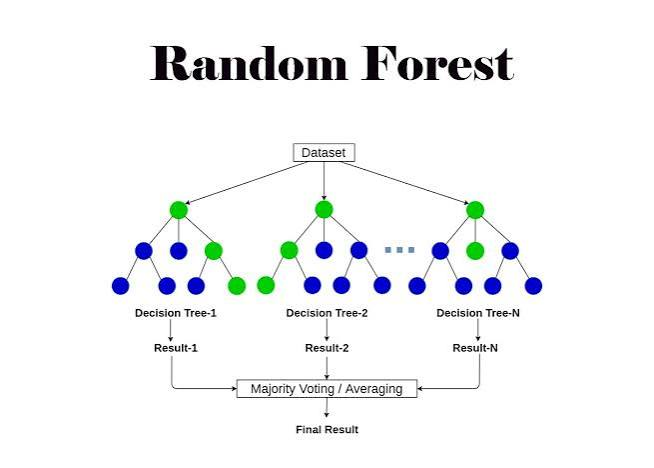

# RandomForestRegressor

```
class sklearn.ensemble.RandomForestRegressor(n_estimators=100, *, criterion='squared_error', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=1.0, max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False, n_jobs=None, random_state=None, verbose=0, warm_start=False, ccp_alpha=0.0, max_samples=None, monotonic_cst=None)
```

`RandomForestRegressor` adalah model regresi ensemble yang terdiri dari banyak pohon keputusan (`DecisionTreeRegressor`). Model ini menggunakan teknik bagging (bootstrap aggregating) untuk meningkatkan akurasi prediksi dan mengurangi overfitting. Setiap pohon dilatih pada subset data yang diambil secara acak dengan penggantian (bootstrap), dan prediksi akhir dihasilkan dengan cara averaging (rata-rata).

## Cara Kerja
1. **Bagging**: Setiap pohon dilatih pada subset data yang diambil secara acak dengan penggantian.
2. **Split Fitur**: Saat mencari split terbaik, hanya subset fitur yang dipertimbangkan (dikontrol oleh `max_features`).
3. **Prediksi**: Prediksi akhir dihasilkan dengan cara averaging dari semua pohon.

## Parameter
- **n_estimators** : int, default=`100`  
  Jumlah pohon dalam hutan.

- **criterion** : {"squared_error", "absolute_error", "friedman_mse", "poisson"}, default=`"squared_error"`  
  Fungsi untuk mengukur kualitas split.  
  - `"squared_error"`: Mean squared error (default).  
  - `"absolute_error"`: Mean absolute error.  
  - `"friedman_mse"`: Mean squared error dengan skor perbaikan Friedman.  
  - `"poisson"`: Pengurangan devians Poisson.

- **max_depth** : int, default=`None`  
  Kedalaman maksimum setiap pohon. Jika `None`, pohon akan berkembang hingga semua daun murni atau memenuhi `min_samples_split`.

- **min_samples_split** : int atau float, default=`2`  
  Jumlah minimum sampel yang diperlukan untuk memisahkan node internal.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_samples_leaf** : int atau float, default=`1`  
  Jumlah minimum sampel yang harus ada di daun.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_weight_fraction_leaf** : float, default=`0.0`  
  Fraksi bobot minimum dari total bobot sampel yang harus ada di daun.

- **max_features** : {"sqrt", "log2"}, int, float, atau `None`, default=`1.0`  
  Jumlah fitur yang dipertimbangkan untuk mencari split terbaik.  
  - Jika `int`, jumlah fitur absolut.  
  - Jika `float`, fraksi dari total fitur.  
  - `"sqrt"`: Menggunakan akar kuadrat dari total fitur.  
  - `"log2"`: Menggunakan logaritma basis 2 dari total fitur.  
  - `None` atau `1.0`: Menggunakan semua fitur.

- **max_leaf_nodes** : int, default=`None`  
  Jumlah maksimum daun. Jika `None`, tidak ada batasan.

- **min_impurity_decrease** : float, default=`0.0`  
  Node akan dipisah jika split mengurangi impurity sebesar nilai ini.

- **bootstrap** : bool, default=`True`  
  Menggunakan bootstrap sampling jika `True`. Jika `False`, seluruh dataset digunakan untuk membangun setiap pohon.

- **oob_score** : bool, default=`False`  
  Menggunakan out-of-bag samples untuk mengestimasi skor generalisasi jika `True`.

- **n_jobs** : int, default=`None`  
  Jumlah pekerjaan paralel. `None` berarti 1, `-1` berarti menggunakan semua prosesor.

- **random_state** : int atau `None`, default=`None`  
  Mengontrol keacakan dalam bootstrap sampling dan pemilihan fitur.

- **verbose** : int, default=`0`  
  Mengontrol verbosity selama fitting dan prediksi.

- **warm_start** : bool, default=`False`  
  Jika `True`, gunakan solusi dari panggilan sebelumnya ke `fit` dan tambahkan lebih banyak estimator.

- **ccp_alpha** : float, default=`0.0`  
  Parameter kompleksitas untuk pruning. Nilai lebih besar menghasilkan pruning lebih agresif.

- **max_samples** : int atau float, default=`None`  
  Jumlah sampel yang digunakan untuk melatih setiap pohon jika `bootstrap=True`.  
  - Jika `int`, jumlah sampel absolut.  
  - Jika `float`, fraksi dari total sampel.

- **monotonic_cst** : array-like of int, shape `(n_features,)`, default=`None`  
  Batasan monotonisitas untuk setiap fitur.  
  - `1`: Meningkat monoton.  
  - `0`: Tidak ada batasan.  
  - `-1`: Menurun monoton.

## Atribut
- **estimator_** : `DecisionTreeRegressor`  
  Template estimator yang digunakan untuk membuat koleksi sub-estimator.

- **estimators_** : list of `DecisionTreeRegressor`  
  Koleksi sub-estimator yang telah dilatih.

- **feature_importances_** : ndarray, shape `(n_features,)`  
  Pentingnya setiap fitur berdasarkan impurity.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting.

- **n_outputs_** : int  
  Jumlah output saat fitting dilakukan.

- **oob_score_** : float  
  Skor generalisasi yang diestimasi menggunakan out-of-bag samples. Hanya tersedia jika `oob_score=True`.

- **oob_prediction_** : ndarray, shape `(n_samples,)` atau `(n_samples, n_outputs)`  
  Prediksi yang dihitung menggunakan out-of-bag samples. Hanya tersedia jika `oob_score=True`.

- **estimators_samples_** : list of arrays  
  Subset sampel yang digunakan untuk setiap estimator.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42)
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 2726.6197169772204
Mean Squared Error: 20705711.57950407
Root Mean Squared Error: 4550.35290713853
R-squared: 0.8666287873624188


#### SVR

<img src = "https://www.researchgate.net/publication/359343222/figure/fig1/AS:1182277103042573@1658888235641/SVM-and-SVR-modeling-In-SVM-left-a-hyperplane-with-maximal-margin-is-constructed-to_W640.jpg" width = 50%></img>

# SVR (Support Vector Regression)

```
class sklearn.svm.SVR(*, kernel='rbf', degree=3, gamma='scale', coef0=0.0, tol=0.001, C=1.0, epsilon=0.1, shrinking=True, cache_size=200, verbose=False, max_iter=-1)
```

`SVR` adalah model regresi yang menggunakan metode Support Vector Machine (SVM) untuk memprediksi nilai kontinu. Model ini bekerja dengan mencari hyperplane yang memaksimalkan margin (jarak) antara titik data dan hyperplane, sambil mengizinkan deviasi sebesar `epsilon` dari nilai sebenarnya.

## Cara Kerja
1. **Kernel Trick**: Menggunakan fungsi kernel untuk memetakan data ke ruang dimensi tinggi di mana hubungan non-linear dapat dimodelkan.
2. **Epsilon-Tube**: Tidak ada penalti untuk titik data yang berada dalam jarak `epsilon` dari nilai prediksi.
3. **Optimisasi**: Meminimalkan fungsi loss yang terdiri dari error prediksi dan regularisasi.

## Parameter
- **kernel** : {"linear", "poly", "rbf", "sigmoid", "precomputed"} atau callable, default=`"rbf"`  
  Jenis kernel yang digunakan.  
  - `"linear"`: Kernel linear.  
  - `"poly"`: Kernel polinomial.  
  - `"rbf"`: Radial Basis Function (default).  
  - `"sigmoid"`: Kernel sigmoid.  
  - `"precomputed"`: Kernel yang sudah dihitung sebelumnya.  
  - Jika callable, digunakan untuk menghitung matriks kernel.

- **degree** : int, default=`3`  
  Derajat kernel polinomial. Hanya berlaku untuk kernel `"poly"`.

- **gamma** : {"scale", "auto"} atau float, default=`"scale"`  
  Koefisien kernel untuk `"rbf"`, `"poly"`, dan `"sigmoid"`.  
  - `"scale"`: Menggunakan `1 / (n_features * X.var())`.  
  - `"auto"`: Menggunakan `1 / n_features`.  
  - Jika float, harus non-negatif.

- **coef0** : float, default=`0.0`  
  Term independen dalam kernel. Hanya signifikan untuk kernel `"poly"` dan `"sigmoid"`.

- **tol** : float, default=`1e-3`  
  Toleransi untuk kriteria penghentian optimisasi.

- **C** : float, default=`1.0`  
  Parameter regularisasi. Kekuatan regularisasi berbanding terbalik dengan nilai `C`. Harus positif.

- **epsilon** : float, default=`0.1`  
  Lebar epsilon-tube. Tidak ada penalti untuk titik data yang berada dalam jarak `epsilon` dari nilai prediksi. Harus non-negatif.

- **shrinking** : bool, default=`True`  
  Menggunakan heuristik shrinking untuk mempercepat optimisasi.

- **cache_size** : float, default=`200`  
  Ukuran cache kernel (dalam MB).

- **verbose** : bool, default=`False`  
  Mengaktifkan output verbose.

- **max_iter** : int, default=`-1`  
  Batas iterasi maksimum untuk solver. `-1` berarti tidak ada batas.

## Atribut
- **coef_** : ndarray, shape `(1, n_features)`  
  Bobot fitur ketika menggunakan kernel `"linear"`.

- **dual_coef_** : ndarray, shape `(1, n_SV)`  
  Koefisien support vector dalam fungsi keputusan.

- **fit_status_** : int  
  `0` jika model berhasil di-fit, `1` jika tidak (akan memunculkan peringatan).

- **intercept_** : ndarray, shape `(1,)`  
  Konstanta dalam fungsi keputusan.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting.

- **n_iter_** : int  
  Jumlah iterasi yang dijalankan oleh rutin optimisasi.

- **n_support_** : ndarray, shape `(1,)`, dtype=int32  
  Jumlah support vector untuk setiap kelas.

- **shape_fit_** : tuple of int, shape `(n_dimensions_of_X,)`  
  Dimensi array dari vektor training `X`.

- **support_** : ndarray, shape `(n_SV,)`  
  Indeks support vector.

- **support_vectors_** : ndarray, shape `(n_SV, n_features)`  
  Support vector.

In [ ]:
from sklearn.svm import SVR
model = SVR()
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 8598.964701526631
Mean Squared Error: 166502152.13488975
Root Mean Squared Error: 12903.571293827525
R-squared: -0.07248639351177277


#### KNN

<img src = "https://miro.medium.com/v2/resize:fit:828/format:webp/1*JBbZ9ert8sML5M3UjgVfoA.png" width = 50%></img>

# KNeighborsRegressor
```
class sklearn.neighbors.KNeighborsRegressor(n_neighbors=5, *, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=None)
```
`KNeighborsRegressor` adalah model regresi yang menggunakan algoritma k-Nearest Neighbors (k-NN). Model ini memprediksi nilai target suatu sampel berdasarkan nilai rata-rata dari k tetangga terdekatnya dalam ruang fitur.

## Cara Kerja
1. **Cari Tetangga Terdekat**: Menghitung jarak antara sampel baru dan semua sampel dalam dataset training.
2. **Interpolasi Lokal**: Memprediksi nilai target dengan mengambil rata-rata (atau rata-rata tertimbang) dari nilai target k tetangga terdekat.

## Parameter
- **n_neighbors** : int, default=`5`  
  Jumlah tetangga terdekat yang digunakan untuk prediksi.

- **weights** : {"uniform", "distance"}, callable, atau `None`, default=`"uniform"`  
  Fungsi bobot yang digunakan dalam prediksi.  
  - `"uniform"`: Semua tetangga memiliki bobot yang sama.  
  - `"distance"`: Tetangga yang lebih dekat memiliki bobot lebih besar.  
  - Jika callable, fungsi yang menerima array jarak dan mengembalikan array bobot.

- **algorithm** : {"auto", "ball_tree", "kd_tree", "brute"}, default=`"auto"`  
  Algoritma yang digunakan untuk mencari tetangga terdekat.  
  - `"ball_tree"`: Menggunakan struktur BallTree.  
  - `"kd_tree"`: Menggunakan struktur KDTree.  
  - `"brute"`: Pencarian brute-force.  
  - `"auto"`: Memilih algoritma secara otomatis berdasarkan data.

- **leaf_size** : int, default=`30`  
  Ukuran leaf untuk BallTree atau KDTree. Memengaruhi kecepatan dan memori.

- **p** : float, default=`2`  
  Parameter untuk metrik Minkowski.  
  - `p=1`: Jarak Manhattan (L1).  
  - `p=2`: Jarak Euclidean (L2).  
  - `p>2`: Jarak Minkowski (Lp).

- **metric** : str, `DistanceMetric`, atau callable, default=`"minkowski"`  
  Metrik yang digunakan untuk menghitung jarak.  
  - `"minkowski"`: Metrik Minkowski (default).  
  - `"euclidean"`, `"manhattan"`, atau metrik lainnya.  
  - Jika callable, fungsi yang menghitung jarak antara dua vektor.

- **metric_params** : dict, default=`None`  
  Parameter tambahan untuk fungsi metrik.

- **n_jobs** : int, default=`None`  
  Jumlah pekerjaan paralel untuk pencarian tetangga.  
  - `None`: 1 pekerjaan.  
  - `-1`: Menggunakan semua prosesor.

## Atribut
- **effective_metric_** : str atau callable  
  Metrik jarak yang digunakan. Sama dengan parameter `metric` atau sinonimnya.

- **effective_metric_params_** : dict  
  Parameter tambahan untuk metrik jarak. Termasuk nilai `p` jika metriknya `"minkowski"`.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting.

- **n_samples_fit_** : int  
  Jumlah sampel dalam data training.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
model = KNeighborsRegressor(n_neighbors=3, weights="distance", metric="euclidean")
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 6127.8123595459765
Mean Squared Error: 107277466.60918196
Root Mean Squared Error: 10357.483604099114
R-squared: 0.3089961793673882


![image.png](https://www.researchgate.net/publication/372511494/figure/fig4/AS:11431281216483760@1704771604649/Flow-chart-of-GBM-model-Zhang-et-al-2021.png))

# GradientBoostingRegressor

```
class sklearn.ensemble.GradientBoostingRegressor(*, loss='squared_error', learning_rate=0.1, n_estimators=100, subsample=1.0, criterion='friedman_mse', min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_depth=3, min_impurity_decrease=0.0, init=None, random_state=None, max_features=None, alpha=0.9, verbose=0, max_leaf_nodes=None, warm_start=False, validation_fraction=0.1, n_iter_no_change=None, tol=0.0001, ccp_alpha=0.0)
```

`GradientBoostingRegressor` adalah model regresi yang menggunakan teknik Gradient Boosting. Model ini membangun model aditif secara bertahap dengan mengoptimalkan fungsi loss yang dapat didiferensiasi. Setiap tahap melibatkan pembuatan pohon regresi yang meminimalkan gradien negatif dari fungsi loss.

## Cara Kerja
1. **Tahap Bertahap**: Model dibangun secara bertahap, di mana setiap tahap menambahkan pohon regresi baru untuk memperbaiki kesalahan prediksi dari tahap sebelumnya.
2. **Optimisasi Loss**: Setiap pohon dilatih pada gradien negatif dari fungsi loss.
3. **Learning Rate**: Kontribusi setiap pohon dikurangi dengan faktor `learning_rate` untuk mencegah overfitting.

## Parameter
- **loss** : {"squared_error", "absolute_error", "huber", "quantile"}, default=`"squared_error"`  
  Fungsi loss yang dioptimalkan.  
  - `"squared_error"`: Loss kuadrat (default).  
  - `"absolute_error"`: Loss absolut (robust).  
  - `"huber"`: Kombinasi loss kuadrat dan absolut.  
  - `"quantile"`: Regresi kuantil (gunakan `alpha` untuk menentukan kuantil).

- **learning_rate** : float, default=`0.1`  
  Tingkat pembelajaran. Mengurangi kontribusi setiap pohon. Harus dalam rentang `[0.0, inf)`.

- **n_estimators** : int, default=`100`  
  Jumlah tahap boosting. Harus dalam rentang `[1, inf)`.

- **subsample** : float, default=`1.0`  
  Fraksi sampel yang digunakan untuk melatih setiap pohon. Jika `< 1.0`, menghasilkan Stochastic Gradient Boosting. Harus dalam rentang `(0.0, 1.0]`.

- **criterion** : {"friedman_mse", "squared_error"}, default=`"friedman_mse"`  
  Fungsi untuk mengukur kualitas split.  
  - `"friedman_mse"`: Mean squared error dengan skor perbaikan Friedman (default).  
  - `"squared_error"`: Mean squared error.

- **min_samples_split** : int atau float, default=`2`  
  Jumlah minimum sampel yang diperlukan untuk memisahkan node internal.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_samples_leaf** : int atau float, default=`1`  
  Jumlah minimum sampel yang harus ada di daun.  
  - Jika `int`, nilai minimum absolut.  
  - Jika `float`, fraksi dari total sampel.

- **min_weight_fraction_leaf** : float, default=`0.0`  
  Fraksi bobot minimum dari total bobot sampel yang harus ada di daun. Harus dalam rentang `[0.0, 0.5]`.

- **max_depth** : int atau `None`, default=`3`  
  Kedalaman maksimum setiap pohon. Jika `None`, pohon akan berkembang hingga semua daun murni atau memenuhi `min_samples_split`.

- **min_impurity_decrease** : float, default=`0.0`  
  Node akan dipisah jika split mengurangi impurity sebesar nilai ini. Harus dalam rentang `[0.0, inf)`.

- **init** : estimator atau `"zero"`, default=`None`  
  Estimator untuk prediksi awal. Jika `"zero"`, prediksi awal diatur ke nol.

- **random_state** : int atau `None`, default=`None`  
  Mengontrol keacakan dalam pembuatan pohon dan split fitur.

- **max_features** : {"sqrt", "log2"}, int, float, atau `None`, default=`None`  
  Jumlah fitur yang dipertimbangkan untuk mencari split terbaik.  
  - Jika `int`, jumlah fitur absolut.  
  - Jika `float`, fraksi dari total fitur.  
  - `"sqrt"`: Menggunakan akar kuadrat dari total fitur.  
  - `"log2"`: Menggunakan logaritma basis 2 dari total fitur.  
  - `None`: Menggunakan semua fitur.

- **alpha** : float, default=`0.9`  
  Parameter kuantil untuk loss `"huber"` atau `"quantile"`. Harus dalam rentang `(0.0, 1.0)`.

- **verbose** : int, default=`0`  
  Mengaktifkan output verbose.  
  - `0`: Tidak ada output.  
  - `1`: Output progres secara berkala.  
  - `>1`: Output progres untuk setiap pohon.

- **max_leaf_nodes** : int, default=`None`  
  Jumlah maksimum daun. Jika `None`, tidak ada batasan.

- **warm_start** : bool, default=`False`  
  Jika `True`, gunakan solusi dari panggilan sebelumnya ke `fit` dan tambahkan lebih banyak estimator.

- **validation_fraction** : float, default=`0.1`  
  Fraksi data training yang digunakan sebagai validation set untuk early stopping. Harus dalam rentang `(0.0, 1.0)`.

- **n_iter_no_change** : int, default=`None`  
  Jumlah iterasi tanpa perbaikan untuk early stopping. Jika `None`, early stopping dinonaktifkan.

- **tol** : float, default=`1e-4`  
  Toleransi untuk early stopping. Harus dalam rentang `[0.0, inf)`.

- **ccp_alpha** : float, default=`0.0`  
  Parameter kompleksitas untuk pruning. Harus dalam rentang `[0.0, inf)`.

## Atribut
- **n_estimators_** : int  
  Jumlah estimator yang dipilih oleh early stopping (jika `n_iter_no_change` diatur).

- **n_trees_per_iteration_** : int  
  Jumlah pohon yang dibangun di setiap iterasi. Untuk regresi, selalu `1`.

- **feature_importances_** : ndarray, shape `(n_features,)`  
  Pentingnya fitur berdasarkan impurity.

- **oob_improvement_** : ndarray, shape `(n_estimators,)`  
  Perbaikan loss pada out-of-bag samples. Hanya tersedia jika `subsample < 1.0`.

- **oob_scores_** : ndarray, shape `(n_estimators,)`  
  Riwayat lengkap nilai loss pada out-of-bag samples. Hanya tersedia jika `subsample < 1.0`.

- **oob_score_** : float  
  Nilai loss terakhir pada out-of-bag samples. Hanya tersedia jika `subsample < 1.0`.

- **train_score_** : ndarray, shape `(n_estimators,)`  
  Nilai loss pada data training di setiap iterasi.

- **init_** : estimator  
  Estimator yang digunakan untuk prediksi awal.

- **estimators_** : ndarray of `DecisionTreeRegressor`, shape `(n_estimators, 1)`  
  Koleksi sub-estimator yang telah dilatih.

- **n_features_in_** : int  
  Jumlah fitur yang digunakan selama fitting.

- **feature_names_in_** : ndarray, shape `(n_features_in_,)`  
  Nama fitur yang digunakan selama fitting.

- **max_features_** : int  
  Nilai `max_features` yang disimpulkan.

![image.png](https://dataaspirant.com/wp-content/uploads/2023/10/1-4-1024x576.png)

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)

Mean Absolute Error: 2405.7538884837604
Mean Squared Error: 18742066.691740826
Root Mean Squared Error: 4329.210862471454
R-squared: 0.8792771669587912


#### All Model

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def train_and_evaluate_regression(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results = {
        'Mean Absolute Error': mean_absolute_error(y_test, y_pred),
        'Mean Squared Error': mean_squared_error(y_test, y_pred),
        'Root Mean Squared Error': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R-squared': r2_score(y_test, y_pred)
    }

    return y_pred, results

def auto_model(X_train, y_train, X_test, y_test):
    models = [
        ('Linear Regression', LinearRegression()),
        ('Support Vector Machine (SVM) Regression', SVR()),
        ('Decision Tree Regression', DecisionTreeRegressor(random_state=12)),
        ('Random Forest Regression', RandomForestRegressor(n_estimators=100, random_state=10)),
        ('K-Nearest Neighbors (KNN) Regression', KNeighborsRegressor(n_neighbors=3)),
        ('Gradient Boosting Regression', GradientBoostingRegressor(n_estimators=100, random_state=10)),
        ('AdaBoost Regression', AdaBoostRegressor(n_estimators=100, random_state=10)),
        ('XGBoost Regression', XGBRegressor(n_estimators=100, random_state=10, verbosity=0)),
        ('LightGBM Regression', LGBMRegressor(n_estimators=100, random_state=10, verbose=-1)),
        ('CatBoost Regression', CatBoostRegressor(iterations=100, depth=6, learning_rate=0.1, random_seed=10, verbose=0)),
        ('Stochastic Gradient Boosting', SGDRegressor(max_iter=1000, tol=1e-3, random_state=10)),
        ('HistGradientBoosting Regression', HistGradientBoostingRegressor(max_iter=100, random_state=10))
    ]

    table = {
        'Model': [],
        'Mean Absolute Error': [],
        'Mean Squared Error': [],
        'Root Mean Squared Error': [],
        'R-squared': []
    }

    for name, model in models:
        y_pred, result = train_and_evaluate_regression(model, X_train, X_test, y_train, y_test)
        table['Model'].append(name)
        table['Mean Absolute Error'].append(result['Mean Absolute Error'])
        table['Mean Squared Error'].append(result['Mean Squared Error'])
        table['Root Mean Squared Error'].append(result['Root Mean Squared Error'])
        table['R-squared'].append(result['R-squared'])

    pd.set_option("display.float_format", "{:.5f}".format)
    return pd.DataFrame(table)


In [ ]:
# Panggil fungsi auto_model dengan X_train, X_test, y_train, y_test
hasil_evaluasi = auto_model(X_train, y_train, X_test, y_test);

In [ ]:
hasil_evaluasi

,Model,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,R-squared
0,Linear Regression,4181.19447,33596915.85136,5796.28466,0.78359
1,Support Vector Machine (SVM) Regression,8598.96470,166502152.13489,12903.57129,-0.07249
2,Decision Tree Regression,3345.76650,50547861.88266,7109.70195,0.67441
3,Random Forest Regression,2530.19538,21393212.71300,4625.27974,0.86220
4,K-Nearest Neighbors (KNN) Regression,6285.78704,109941146.97943,10485.28240,0.29184
5,Gradient Boosting Regression,2398.76503,18708575.96159,4325.34114,0.87949
6,AdaBoost Regression,4194.02239,26840430.83444,5180.77512,0.82711
7,XGBoost Regression,2800.30798,24504995.01079,4950.25201,0.84216
8,LightGBM Regression,2605.88811,20899408.80014,4571.58712,0.86538
9,CatBoost Regression,2461.31840,19114371.29142,4371.99855,0.87688


#### Cross Validation

In [ ]:
import warnings
import pandas as pd
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def train_and_evaluate_regression(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results = {
        'Mean Absolute Error': round(mean_absolute_error(y_test, y_pred), 5),
        'Mean Squared Error': round(mean_squared_error(y_test, y_pred), 5),
        'Root Mean Squared Error': round(np.sqrt(mean_squared_error(y_test, y_pred)), 5),
        'R-squared': round(r2_score(y_test, y_pred), 5)
    }

    return y_pred, results

def auto_model(X_train, y_train, X_test, y_test):
    # Pastikan data terstandarisasi untuk model seperti SVM dan SGD
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    models = [
        ('Linear Regression', LinearRegression()),
        ('Support Vector Machine (SVM) Regression', SVR()),
        ('Decision Tree Regression', DecisionTreeRegressor(random_state=12)),
        ('Random Forest Regression', RandomForestRegressor(n_estimators=100, random_state=10)),
        ('K-Nearest Neighbors (KNN) Regression', KNeighborsRegressor(n_neighbors=3)),
        ('Gradient Boosting Regression', GradientBoostingRegressor(n_estimators=100, random_state=10)),
        ('AdaBoost Regression', AdaBoostRegressor(n_estimators=100, random_state=10)),
        ('XGBoost Regression', XGBRegressor(n_estimators=100, random_state=10, verbosity=0)),
        ('LightGBM Regression', LGBMRegressor(n_estimators=100, random_state=10, verbose=-1)),
        ('CatBoost Regression', CatBoostRegressor(iterations=100, depth=6, learning_rate=0.1, random_seed=10, verbose=0)),
        ('Stochastic Gradient Boosting', SGDRegressor(max_iter=1000, tol=1e-3, random_state=10)),
        ('HistGradientBoosting Regression', HistGradientBoostingRegressor(max_iter=100, random_state=10))
    ]

    table = {
        'Model': [],
        'Mean Absolute Error': [],
        'Mean Squared Error': [],
        'Root Mean Squared Error': [],
        'R-squared': [],
        'Cross-validated R-squared': []
    }

    for name, model in models:
        print(f"Training {name}...")

        # Gunakan data yang sudah distandarisasi untuk model tertentu
        if isinstance(model, (SVR, SGDRegressor)):
            X_train_input, X_test_input = X_train_scaled, X_test_scaled
        else:
            X_train_input, X_test_input = X_train, X_test

        y_pred, result = train_and_evaluate_regression(model, X_train_input, X_test_input, y_train, y_test)

        table['Model'].append(name)
        table['Mean Absolute Error'].append(result['Mean Absolute Error'])
        table['Mean Squared Error'].append(result['Mean Squared Error'])
        table['Root Mean Squared Error'].append(result['Root Mean Squared Error'])
        table['R-squared'].append(result['R-squared'])

        # Evaluasi performa model menggunakan validasi silang
        try:
            if name != "CatBoost Regression":  # CatBoost memiliki cara validasi sendiri
                cv_scores = cross_val_score(model, X_train_input, y_train, cv=5, scoring='r2')
                avg_cv_score = round(cv_scores.mean(), 5)
                table['Cross-validated R-squared'].append(avg_cv_score)
            else:
                table['Cross-validated R-squared'].append("N/A")
        except Exception as e:
            warnings.warn(f"Cross-validation gagal untuk {name} dengan error: {str(e)}")
            table['Cross-validated R-squared'].append("Error")

    result_df = pd.DataFrame(table)
    result_df = result_df.sort_values(by='R-squared', ascending=False).reset_index(drop=True)

    pd.set_option("display.float_format", "{:.5f}".format)

    return result_df


In [ ]:
# Panggil fungsi auto_model dengan X_train, X_test, y_train, y_test
hasil = auto_model(X_train, y_train, X_test, y_test);

Training Linear Regression...
Training Support Vector Machine (SVM) Regression...
Training Decision Tree Regression...
Training Random Forest Regression...
Training K-Nearest Neighbors (KNN) Regression...
Training Gradient Boosting Regression...
Training AdaBoost Regression...
Training XGBoost Regression...


C:\Users\acer\AppData\Local\Temp\ipykernel_15528\365157130.py:85: UserWarning: Cross-validation gagal untuk XGBoost Regression dengan error: 'super' object has no attribute '__sklearn_tags__'
  warnings.warn(f"Cross-validation gagal untuk {name} dengan error: {str(e)}")


Training LightGBM Regression...
Training CatBoost Regression...
Training Stochastic Gradient Boosting...
Training HistGradientBoosting Regression...


In [ ]:
# Panggil fungsi auto_model dengan X_train, X_test, y_train, y_test
hasil

,Model,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,R-squared,Cross-validated R-squared
0,Gradient Boosting Regression,2398.76503,18708575.96159,4325.34114,0.87949,0.84102
1,CatBoost Regression,2461.31840,19114371.29142,4371.99855,0.87688,N/A
2,LightGBM Regression,2605.88811,20899408.80014,4571.58712,0.86538,0.82219
3,Random Forest Regression,2530.19538,21393212.71300,4625.27974,0.86220,0.82747
4,HistGradientBoosting Regression,2639.60334,21506747.56182,4637.53680,0.86147,0.82157
5,XGBoost Regression,2800.30798,24504995.01079,4950.25201,0.84216,Error
6,AdaBoost Regression,4194.02239,26840430.83444,5180.77512,0.82711,0.78925
7,Stochastic Gradient Boosting,4168.99356,33563903.71947,5793.43626,0.78381,0.73258
8,Linear Regression,4181.19447,33596915.85136,5796.28466,0.78359,0.73311
9,Decision Tree Regression,3345.76650,50547861.88266,7109.70195,0.67441,0.70227
